In [1]:
print("Hello Analytics")

Hello Analytics


In [2]:
import os

print("Current Directory:")
print(os.getcwd())

print("\nProject Files:")
print(os.listdir())

Current Directory:
c:\Users\DELL\india-wind-solar-resource-estimator\src

Project Files:
['analytics.ipynb', 'analyzer.py', 'ingestion.py', 'visualizer.py', '__init__.py']


In [3]:
from pathlib import Path

file_path = Path("ingestion.py")

with open(file_path, "r", encoding="utf-8") as file:
    ingestion_code = file.read()

print(ingestion_code)

import csv
from pathlib import Path
from datetime import datetime

def validate_record(row):
    try:
        temp_max = float(row["temp_max"])
        temp_min = float(row["temp_min"])
        wind_speed = float(row["wind_speed_kmh"])
        pressure = float(row["pressure_hpa"])

        if not (-5 <= temp_max <= 55):
            raise ValueError("Maximum temperature out of range")

        if not (-5 <= temp_min <= 55):
            raise ValueError("Minimum temperature out of range")

        if wind_speed < 0:
            raise ValueError("Negative wind speed")

        if not (900 <= pressure <= 1050):
            raise ValueError("Pressure out of range")

        if temp_min > temp_max:
            raise ValueError("Minimum temperature exceeds maximum")

        date_value = row["date"].strip()

        try:
            datetime.strptime(date_value, "%Y-%m-%d")
        except ValueError:
            datetime.strptime(date_value, "%m/%d/%Y")

        return True, "Valid record"

 

In [4]:
from pathlib import Path

project_root = Path.cwd().parent

csv_files = list(project_root.rglob("*.csv"))

print("CSV files available in project:\n")

for file in csv_files:
    print(file)

CSV files available in project:

c:\Users\DELL\india-wind-solar-resource-estimator\data\processed\clean_india_weather_25yr.csv
c:\Users\DELL\india-wind-solar-resource-estimator\data\raw\india_daily_weather_2000_2024_raw.csv


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
file_path = "../data/processed/clean_india_weather_25yr.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

# Display first 5 records
df.head()

Dataset loaded successfully!
Shape of dataset: (91320, 13)


,city,date,temp_max,temp_min,wind_speed_kmh,pressure_hpa,sunshine_hours,rainfall_mm,apparent_temperature_max,apparent_temperature_min,weather_code,wind_gusts_10m_max,wind_direction_10m_dominant
0,Ahmedabad,1/1/2000,29.9,15.3,14.5,1007.21,10.28,0.0,29.1,12.8,0,30.2,60
1,Ahmedabad,1/2/2000,29.9,16.1,15.3,1007.79,10.35,0.0,28.8,13.2,0,29.5,68
2,Ahmedabad,1/3/2000,29.1,15.1,14.4,1007.48,10.42,0.0,27.9,12.1,0,27.7,52
3,Ahmedabad,1/4/2000,28.6,13.7,12.4,1007.03,10.42,0.0,27.5,11.2,0,21.6,45
4,Ahmedabad,1/5/2000,28.1,13.2,11.3,1008.05,10.49,0.0,26.8,10.8,0,22.7,34


In [6]:
# Dataset information
df.info()

# Statistical summary
df.describe()

# Column names
print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 91320 entries, 0 to 91319
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   city                         91320 non-null  str    
 1   date                         91320 non-null  str    
 2   temp_max                     91320 non-null  float64
 3   temp_min                     91320 non-null  float64
 4   wind_speed_kmh               91320 non-null  float64
 5   pressure_hpa                 91320 non-null  float64
 6   sunshine_hours               91320 non-null  float64
 7   rainfall_mm                  91320 non-null  float64
 8   apparent_temperature_max     91320 non-null  float64
 9   apparent_temperature_min     91320 non-null  float64
 10  weather_code                 91320 non-null  int64  
 11  wind_gusts_10m_max           91320 non-null  float64
 12  wind_direction_10m_dominant  91320 non-null  int64  
dtypes: float64(9), int64(2), st

In [7]:
# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 3. Number of cities
print("\nTotal Cities:")
print(df["city"].nunique())

# 4. City names
print("\nCity Names:")
print(df["city"].unique())

# 5. Date range
df["date"] = pd.to_datetime(df["date"])

print("\nDate Range:")
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Missing Values:
city                           0
date                           0
temp_max                       0
temp_min                       0
wind_speed_kmh                 0
pressure_hpa                   0
sunshine_hours                 0
rainfall_mm                    0
apparent_temperature_max       0
apparent_temperature_min       0
weather_code                   0
wind_gusts_10m_max             0
wind_direction_10m_dominant    0
dtype: int64

Duplicate Records:
0

Total Cities:
10

City Names:
<ArrowStringArray>
['Ahmedabad', 'Bangalore',   'Chennai',     'Delhi', 'Hyderabad',    'Jaipur',
   'Kolkata',   'Lucknow',    'Mumbai',      'Pune']
Length: 10, dtype: str

Date Range:
Start Date: 2000-01-01 00:00:00
End Date: 2024-12-31 00:00:00


In [8]:
print(df.isnull().sum())

city                           0
date                           0
temp_max                       0
temp_min                       0
wind_speed_kmh                 0
pressure_hpa                   0
sunshine_hours                 0
rainfall_mm                    0
apparent_temperature_max       0
apparent_temperature_min       0
weather_code                   0
wind_gusts_10m_max             0
wind_direction_10m_dominant    0
dtype: int64


In [9]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [10]:
print("Total Cities:", df["city"].nunique())

Total Cities: 10


In [11]:
print(df["city"].unique().tolist())

['Ahmedabad', 'Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Pune']


In [12]:
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2000-01-01 00:00:00
End Date: 2024-12-31 00:00:00


In [13]:
# City-wise average wind speed

city_wind = df.groupby("city")["wind_speed_kmh"].agg(
    ["mean", "max", "min"]
)

city_wind = city_wind.sort_values(
    by="mean",
    ascending=False
)

print("CITY-WISE WIND SPEED ANALYSIS")

display(city_wind.round(2))

CITY-WISE WIND SPEED ANALYSIS


,mean,max,min
city,,,
Chennai,18.36,65.2,6.9
Mumbai,18.02,61.9,6.5
Bangalore,16.55,42.6,4.2
Hyderabad,15.99,37.9,5.4
Pune,14.69,49.1,3.6
Delhi,14.66,37.9,4.3
Jaipur,14.66,42.0,4.9
Lucknow,14.59,41.0,4.9
Ahmedabad,14.19,57.5,5.4


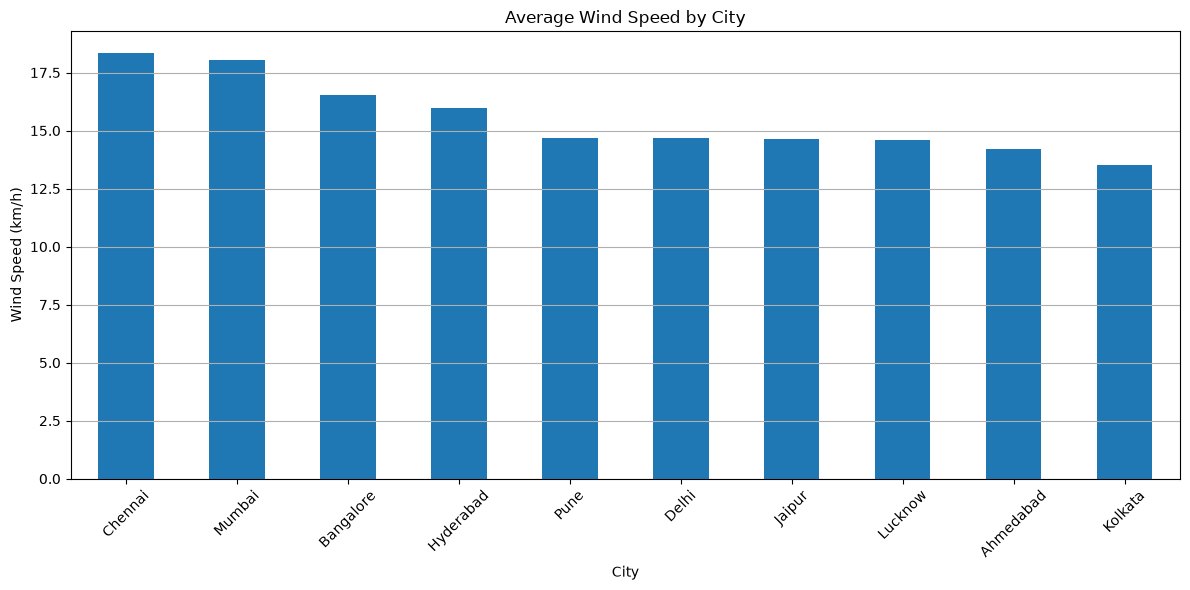

In [14]:
plt.figure(figsize=(12, 6))

city_wind["mean"].plot(
    kind="bar",
    title="Average Wind Speed by City",
    xlabel="City",
    ylabel="Wind Speed (km/h)"
)

plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [15]:
highest_city = city_wind["mean"].idxmax()
lowest_city = city_wind["mean"].idxmin()

print("Highest Average Wind Speed City:", highest_city)
print("Highest Average Wind Speed:",
      round(city_wind.loc[highest_city, "mean"], 2), "km/h")

print("\nLowest Average Wind Speed City:", lowest_city)
print("Lowest Average Wind Speed:",
      round(city_wind.loc[lowest_city, "mean"], 2), "km/h")

Highest Average Wind Speed City: Chennai
Highest Average Wind Speed: 18.36 km/h

Lowest Average Wind Speed City: Kolkata
Lowest Average Wind Speed: 13.52 km/h


In [16]:
# Calculate average temperature
df["avg_temperature"] = (
    df["temp_max"] + df["temp_min"]
) / 2

# Convert Celsius to Kelvin
df["temp_kelvin"] = df["avg_temperature"] + 273.15

# Convert pressure from hPa to Pa
df["pressure_pa"] = df["pressure_hpa"] * 100

# Convert wind speed from km/h to m/s
df["wind_speed_ms"] = df["wind_speed_kmh"] / 3.6

# Calculate air density
df["air_density"] = (
    df["pressure_pa"] /
    (287.05 * df["temp_kelvin"])
)

# Calculate wind power density
df["wind_power_density"] = (
    0.5 * df["air_density"] *
    (df["wind_speed_ms"] ** 3)
)

print("Wind Power Density calculated successfully!")

display(
    df[["city", "wind_speed_ms",
        "air_density", "wind_power_density"]].head()
)

Wind Power Density calculated successfully!


,city,wind_speed_ms,air_density,wind_power_density
0,Ahmedabad,4.027778,1.186418,38.761826
1,Ahmedabad,4.250000,1.185498,45.502740
2,Ahmedabad,4.000000,1.188746,38.039864
3,Ahmedabad,3.444444,1.192050,24.356908
4,Ahmedabad,3.138889,1.195288,18.482919


In [17]:
city_wpd = df.groupby("city")[
    "wind_power_density"
].mean().sort_values(ascending=False)

print("CITY-WISE WIND POWER DENSITY")

display(city_wpd.round(2))

CITY-WISE WIND POWER DENSITY


city
Chennai      90.86
Mumbai       89.74
Bangalore    69.83
Hyderabad    69.32
Lucknow      55.35
Delhi        52.41
Pune         51.35
Jaipur       50.59
Ahmedabad    46.27
Kolkata      44.71
Name: wind_power_density, dtype: float64

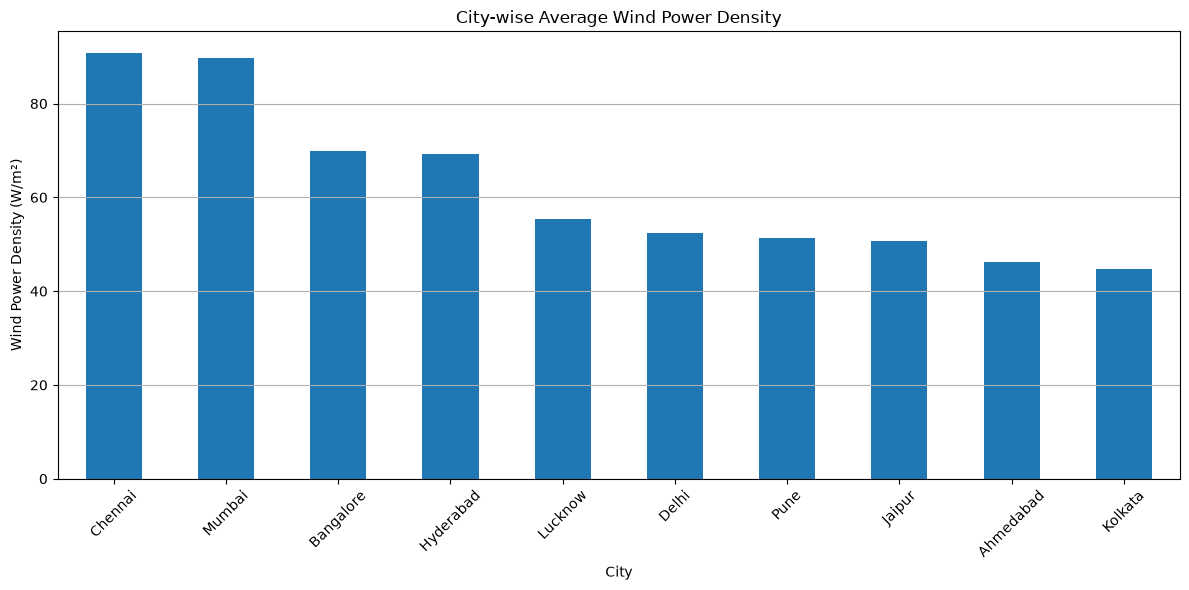

In [18]:
plt.figure(figsize=(12, 6))

city_wpd.plot(kind="bar")

plt.title("City-wise Average Wind Power Density")
plt.xlabel("City")
plt.ylabel("Wind Power Density (W/m²)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [19]:
# City-wise average sunshine hours

city_solar = df.groupby("city")["sunshine_hours"].agg(
    ["mean", "max", "min"]
)

city_solar = city_solar.sort_values(
    by="mean",
    ascending=False
)

print("CITY-WISE SOLAR RESOURCE ANALYSIS")

display(city_solar.round(2))

CITY-WISE SOLAR RESOURCE ANALYSIS


,mean,max,min
city,,,
Delhi,10.38,13.32,0.0
Jaipur,10.38,12.98,0.0
Ahmedabad,10.10,12.55,0.0
Lucknow,10.08,13.00,0.0
Chennai,9.93,12.68,0.0
Hyderabad,9.83,12.64,0.0
Mumbai,9.76,12.23,0.0
Bangalore,9.74,12.22,0.0
Pune,9.68,12.11,0.0


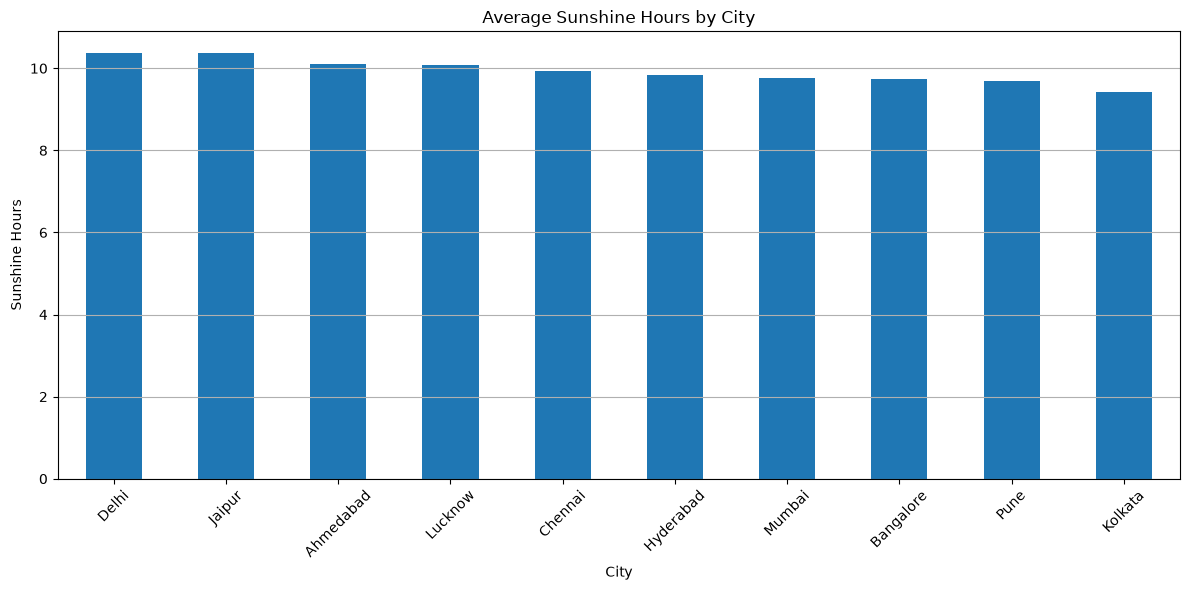

In [20]:
plt.figure(figsize=(12, 6))

city_solar["mean"].plot(kind="bar")

plt.title("Average Sunshine Hours by City")
plt.xlabel("City")
plt.ylabel("Sunshine Hours")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [21]:
highest_solar_city = city_solar["mean"].idxmax()
lowest_solar_city = city_solar["mean"].idxmin()

print("Highest Sunshine City:", highest_solar_city)

print("Average Sunshine Hours:",
      round(city_solar.loc[highest_solar_city, "mean"], 2))

print("\nLowest Sunshine City:", lowest_solar_city)

print("Average Sunshine Hours:",
      round(city_solar.loc[lowest_solar_city, "mean"], 2))

Highest Sunshine City: Delhi
Average Sunshine Hours: 10.38

Lowest Sunshine City: Kolkata
Average Sunshine Hours: 9.43


In [22]:
# Extract year from date

df["year"] = df["date"].dt.year

print("Year column created successfully!")

print(df[["date", "year"]].head())

Year column created successfully!
        date  year
0 2000-01-01  2000
1 2000-01-02  2000
2 2000-01-03  2000
3 2000-01-04  2000
4 2000-01-05  2000


In [23]:
yearly_wind = df.groupby("year")[
    "wind_speed_kmh"
].mean()

print("YEAR-WISE AVERAGE WIND SPEED")

display(yearly_wind.round(2))

YEAR-WISE AVERAGE WIND SPEED


year
2000    15.05
2001    15.01
2002    15.46
2003    15.05
2004    15.24
2005    15.09
2006    15.04
2007    15.00
2008    14.64
2009    15.26
2010    14.76
2011    14.78
2012    15.22
2013    15.20
2014    15.04
2015    14.75
2016    14.80
2017    16.75
2018    16.76
2019    16.82
2020    16.18
2021    16.24
2022    16.80
2023    16.71
2024    16.44
Name: wind_speed_kmh, dtype: float64

In [24]:
yearly_sunshine = df.groupby("year")[
    "sunshine_hours"
].mean()

print("YEAR-WISE AVERAGE SUNSHINE HOURS")

display(yearly_sunshine.round(2))

YEAR-WISE AVERAGE SUNSHINE HOURS


year
2000    10.17
2001    10.14
2002    10.30
2003     9.97
2004    10.17
2005    10.04
2006    10.14
2007     9.99
2008     9.91
2009    10.20
2010     9.75
2011     9.96
2012    10.08
2013     9.72
2014    10.17
2015    10.15
2016     9.89
2017     9.92
2018     9.71
2019     9.62
2020     9.68
2021     9.62
2022     9.68
2023     9.89
2024     9.44
Name: sunshine_hours, dtype: float64

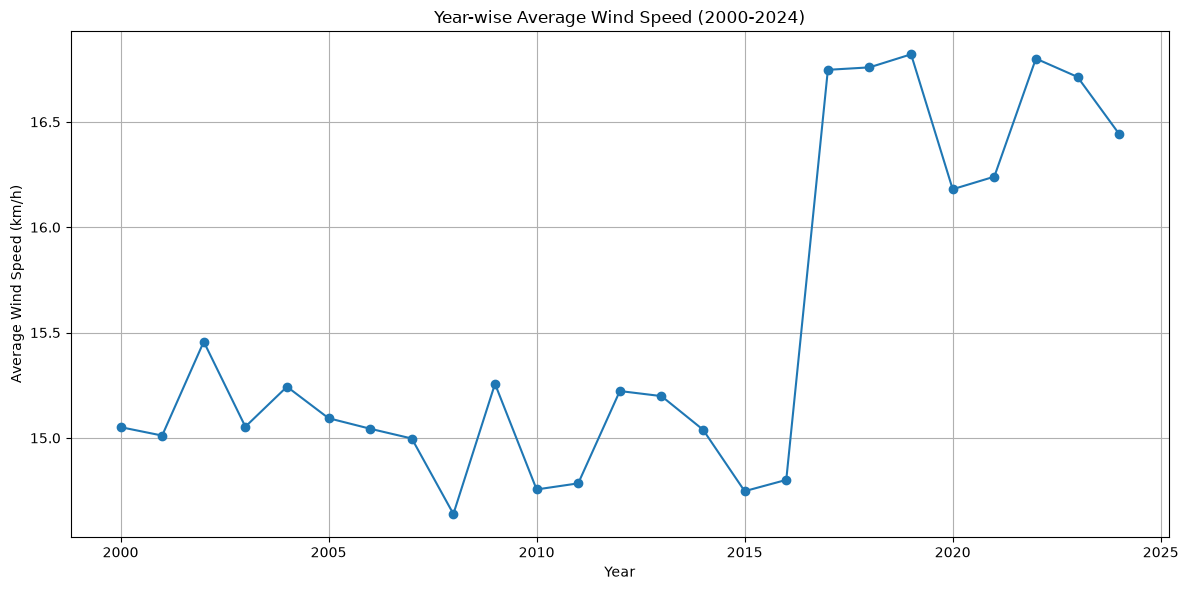

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_wind.index,
    yearly_wind.values,
    marker="o"
)

plt.title("Year-wise Average Wind Speed (2000-2024)")
plt.xlabel("Year")
plt.ylabel("Average Wind Speed (km/h)")
plt.grid(True)
plt.tight_layout()
plt.show()

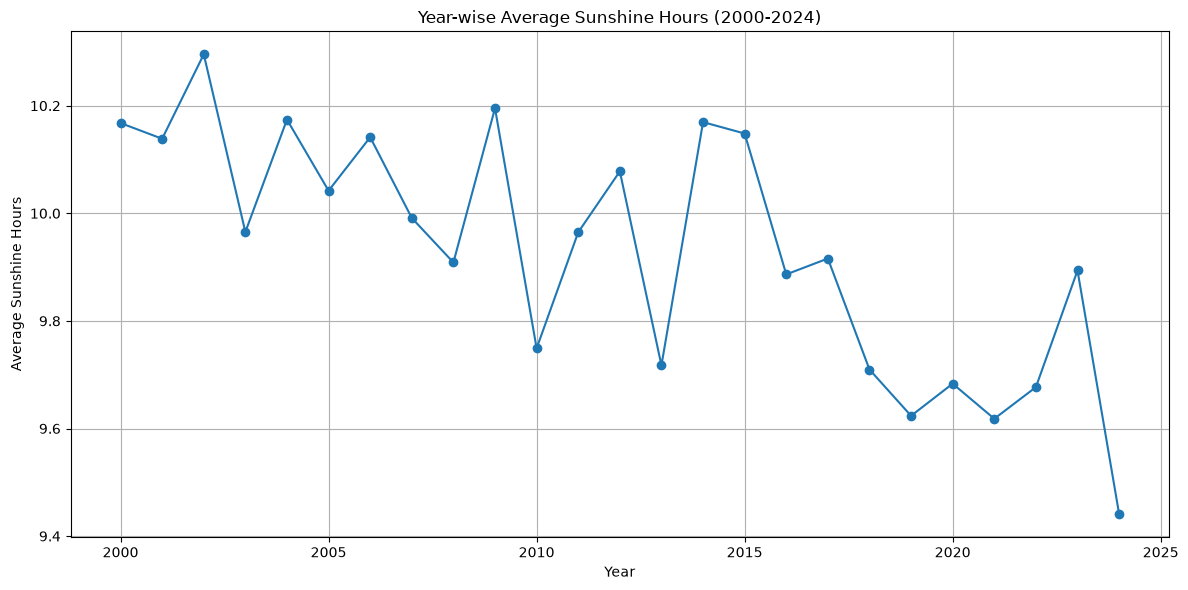

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_sunshine.index,
    yearly_sunshine.values,
    marker="o"
)

plt.title("Year-wise Average Sunshine Hours (2000-2024)")
plt.xlabel("Year")
plt.ylabel("Average Sunshine Hours")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


df["month"] = df["date"].dt.month

df["season"] = df["month"].apply(get_season)

print("Season column created successfully!")

display(df[["date", "month", "season"]].head(10))

Season column created successfully!


,date,month,season
0,2000-01-01,1,Winter
1,2000-01-02,1,Winter
2,2000-01-03,1,Winter
3,2000-01-04,1,Winter
4,2000-01-05,1,Winter
5,2000-01-06,1,Winter
6,2000-01-07,1,Winter
7,2000-01-08,1,Winter
8,2000-01-09,1,Winter
9,2000-01-10,1,Winter


In [28]:
seasonal_wind = df.groupby("season")[
    "wind_speed_kmh"
].mean()

print("SEASONAL AVERAGE WIND SPEED")

display(seasonal_wind.round(2))

SEASONAL AVERAGE WIND SPEED


season
Monsoon         17.67
Post-Monsoon    12.51
Summer          16.76
Winter          13.40
Name: wind_speed_kmh, dtype: float64

In [29]:
seasonal_sunshine = df.groupby("season")[
    "sunshine_hours"
].mean()

print("SEASONAL AVERAGE SUNSHINE HOURS")

display(seasonal_sunshine.round(2))

SEASONAL AVERAGE SUNSHINE HOURS


season
Monsoon          8.49
Post-Monsoon     9.93
Summer          11.57
Winter          10.21
Name: sunshine_hours, dtype: float64

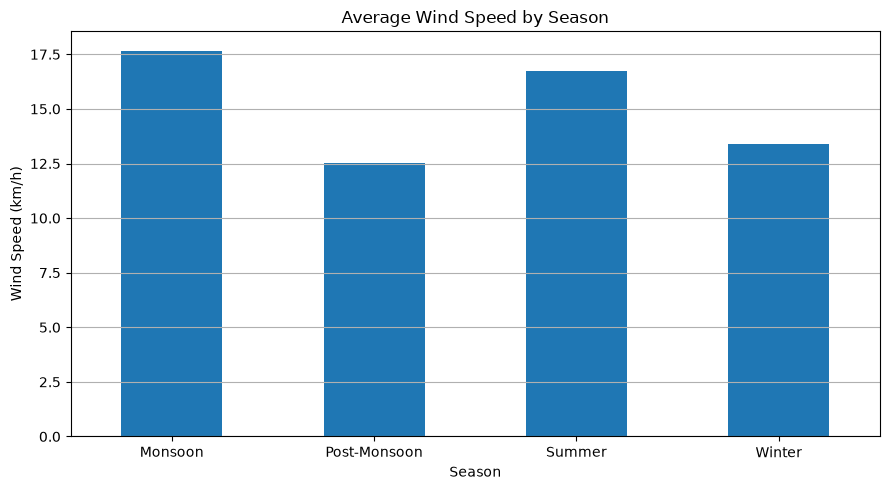

In [30]:
plt.figure(figsize=(9, 5))

seasonal_wind.plot(kind="bar")

plt.title("Average Wind Speed by Season")
plt.xlabel("Season")
plt.ylabel("Wind Speed (km/h)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

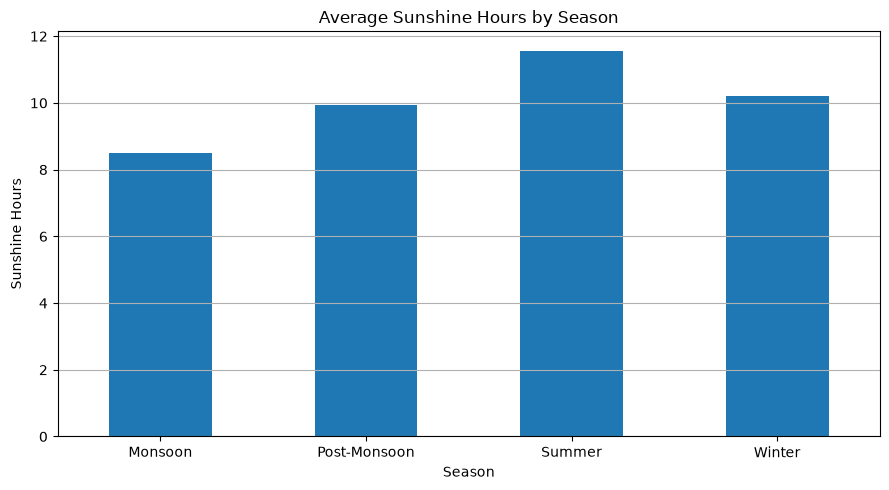

In [31]:
plt.figure(figsize=(9, 5))

seasonal_sunshine.plot(kind="bar")

plt.title("Average Sunshine Hours by Season")
plt.xlabel("Season")
plt.ylabel("Sunshine Hours")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [32]:
seasonal_wpd = df.pivot_table(
    index="city",
    columns="season",
    values="wind_power_density",
    aggfunc="mean"
)

print("CITY-WISE SEASONAL WIND POWER DENSITY")

display(seasonal_wpd.round(2))

CITY-WISE SEASONAL WIND POWER DENSITY


season,Monsoon,Post-Monsoon,Summer,Winter
city,,,,
Ahmedabad,66.47,20.10,50.68,32.14
Bangalore,123.22,42.09,41.58,45.21
Chennai,92.66,80.24,103.12,83.12
Delhi,57.84,27.06,76.11,38.03
Hyderabad,135.51,31.28,48.24,27.06
Jaipur,66.28,22.41,73.04,25.56
Kolkata,58.31,19.38,69.00,18.68
Lucknow,66.62,22.07,84.06,33.37
Mumbai,131.47,38.76,98.01,59.39


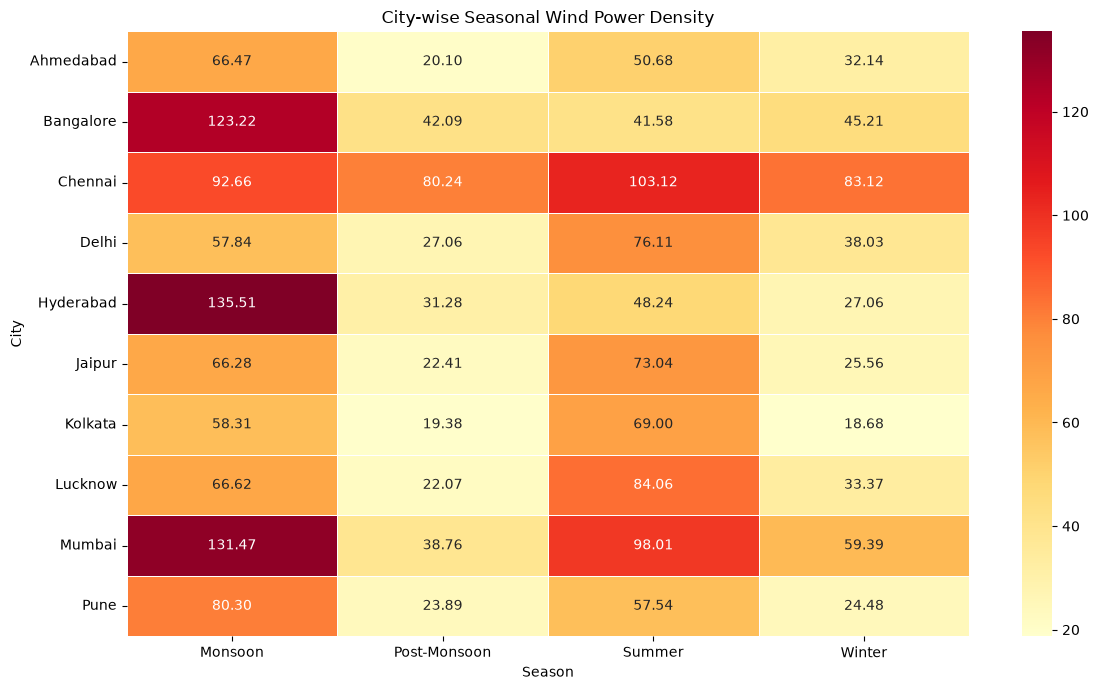

In [33]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    seasonal_wpd,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("City-wise Seasonal Wind Power Density")
plt.xlabel("Season")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [34]:
best_season = seasonal_wpd.idxmax(axis=1)

print("BEST WIND ENERGY SEASON FOR EACH CITY")

display(best_season)

BEST WIND ENERGY SEASON FOR EACH CITY


city
Ahmedabad    Monsoon
Bangalore    Monsoon
Chennai       Summer
Delhi         Summer
Hyderabad    Monsoon
Jaipur        Summer
Kolkata       Summer
Lucknow       Summer
Mumbai       Monsoon
Pune         Monsoon
dtype: str

In [35]:
# Select numerical columns for correlation

correlation_data = df[
    [
        "temp_max",
        "temp_min",
        "wind_speed_kmh",
        "pressure_hpa",
        "sunshine_hours",
        "rainfall_mm",
        "wind_gusts_10m_max",
        "wind_power_density"
    ]
]

# Calculate correlation matrix

correlation_matrix = correlation_data.corr()

print("CORRELATION MATRIX")

display(correlation_matrix.round(2))

CORRELATION MATRIX


,temp_max,temp_min,wind_speed_kmh,pressure_hpa,sunshine_hours,rainfall_mm,wind_gusts_10m_max,wind_power_density
temp_max,1.00,0.70,0.18,0.08,0.42,-0.17,0.16,0.08
temp_min,0.70,1.00,0.39,0.13,-0.04,0.18,0.37,0.29
wind_speed_kmh,0.18,0.39,1.00,-0.06,-0.13,0.18,0.91,0.88
pressure_hpa,0.08,0.13,-0.06,1.00,0.04,-0.00,-0.21,-0.03
sunshine_hours,0.42,-0.04,-0.13,0.04,1.00,-0.60,-0.15,-0.18
rainfall_mm,-0.17,0.18,0.18,-0.00,-0.60,1.00,0.21,0.26
wind_gusts_10m_max,0.16,0.37,0.91,-0.21,-0.15,0.21,1.00,0.80
wind_power_density,0.08,0.29,0.88,-0.03,-0.18,0.26,0.80,1.00


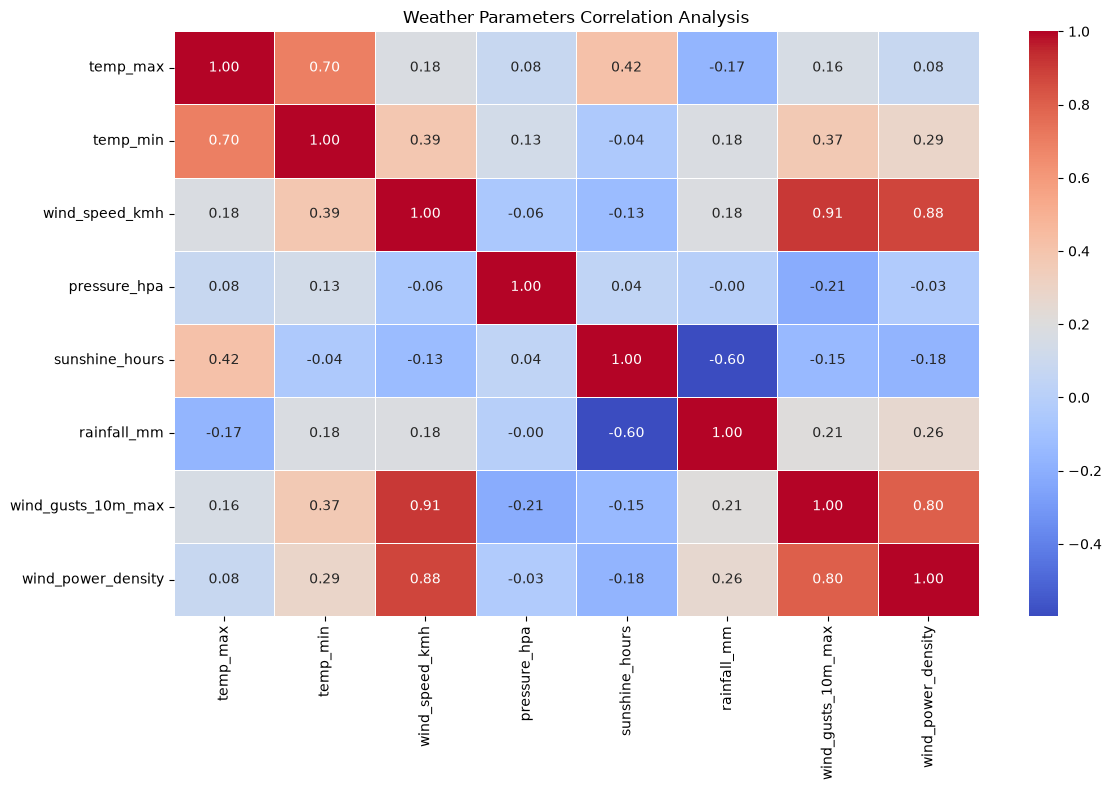

In [36]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Weather Parameters Correlation Analysis")

plt.tight_layout()
plt.show()

In [37]:
# Get correlations with wind power density

wpd_correlation = correlation_matrix[
    "wind_power_density"
].sort_values(ascending=False)

print("CORRELATION WITH WIND POWER DENSITY")

display(wpd_correlation.round(3))

CORRELATION WITH WIND POWER DENSITY


wind_power_density    1.000
wind_speed_kmh        0.881
wind_gusts_10m_max    0.804
temp_min              0.287
rainfall_mm           0.257
temp_max              0.082
pressure_hpa         -0.031
sunshine_hours       -0.179
Name: wind_power_density, dtype: float64

In [38]:
resource_comparison = df.groupby("city").agg(
    avg_wind_power_density=("wind_power_density", "mean"),
    avg_sunshine_hours=("sunshine_hours", "mean")
)

resource_comparison = resource_comparison.sort_values(
    by="avg_wind_power_density",
    ascending=False
)

display(resource_comparison.round(2))

,avg_wind_power_density,avg_sunshine_hours
city,,
Chennai,90.86,9.93
Mumbai,89.74,9.76
Bangalore,69.83,9.74
Hyderabad,69.32,9.83
Lucknow,55.35,10.08
Delhi,52.41,10.38
Pune,51.35,9.68
Jaipur,50.59,10.38
Ahmedabad,46.27,10.10


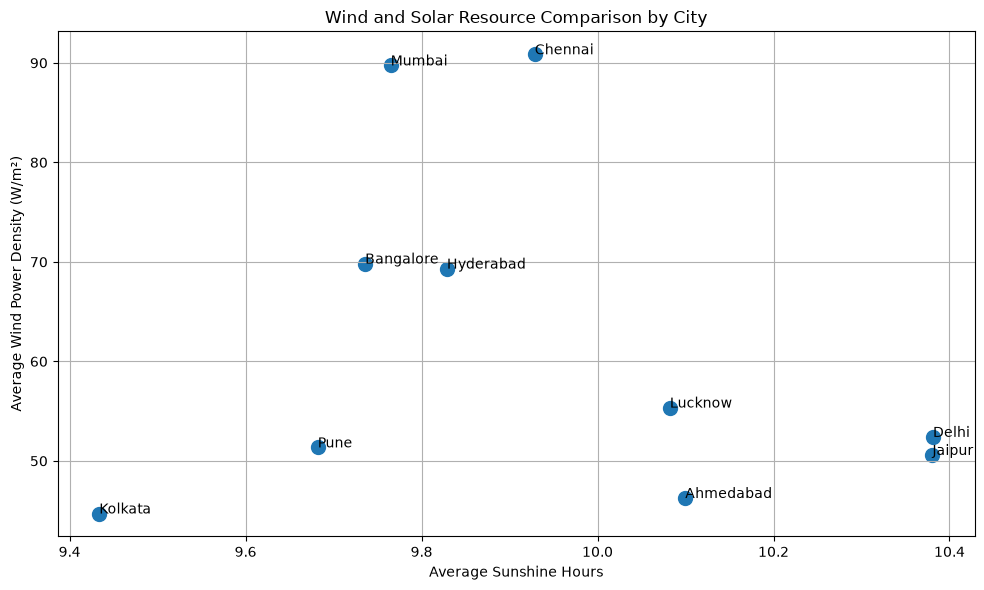

In [39]:
plt.figure(figsize=(10, 6))

plt.scatter(
    resource_comparison["avg_sunshine_hours"],
    resource_comparison["avg_wind_power_density"],
    s=100
)

for city in resource_comparison.index:
    plt.annotate(
        city,
        (
            resource_comparison.loc[city, "avg_sunshine_hours"],
            resource_comparison.loc[city, "avg_wind_power_density"]
        )
    )

plt.title("Wind and Solar Resource Comparison by City")
plt.xlabel("Average Sunshine Hours")
plt.ylabel("Average Wind Power Density (W/m²)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
print("Highest Wind Power Density City:")
print(resource_comparison["avg_wind_power_density"].idxmax())

print("\nHighest Sunshine Hours City:")
print(resource_comparison["avg_sunshine_hours"].idxmax())

Highest Wind Power Density City:
Chennai

Highest Sunshine Hours City:
Delhi
